In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

In [4]:
df = df.drop_duplicates()
df = df.dropna()

In [5]:
X = df.drop("target", axis=1)
y = df["target"]

In [6]:
X = pd.get_dummies(X, drop_first=True)
X = X.astype(float).values
y = y.astype(int).values

In [7]:
np.random.seed(42)

indices = np.random.permutation(len(X))
X = X[indices]
y = y[indices]

split = int(0.8 * len(X))

X_train = X[:split]
X_val = X[split:]

y_train = y[:split]
y_val = y[split:]

In [8]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1

X_train = (X_train - mean) / std
X_val = (X_val - mean) / std

In [9]:
input_size = X_train.shape[1]
hidden_size = 16
output_size = 1

learning_rate = 0.01
epochs = 200

In [10]:
W1 = np.random.randn(input_size, hidden_size) * 0.1
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * 0.1
b2 = np.zeros((1, output_size))

In [11]:
training_losses = []
validation_losses = []

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def calculate_loss(y_true, y_pred):
    epsilon = 1e-8
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [12]:
for epoch in range(epochs):

    Z1 = X_train @ W1 + b1
    A1 = np.maximum(0, Z1)

    Z2 = A1 @ W2 + b2
    train_predictions = sigmoid(Z2)

    train_loss = calculate_loss(
        y_train.reshape(-1, 1),
        train_predictions
    )

    # Forward pass on validation data
    V1 = X_val @ W1 + b1
    VA1 = np.maximum(0, V1)

    V2 = VA1 @ W2 + b2
    val_predictions = sigmoid(V2)

    val_loss = calculate_loss(
        y_val.reshape(-1, 1),
        val_predictions
    )


    training_losses.append(train_loss)
    validation_losses.append(val_loss)

    m = len(X_train)

    dZ2 = train_predictions - y_train.reshape(-1, 1)
    dW2 = (A1.T @ dZ2) / m
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = (X_train.T @ dZ1) / m
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if (epoch + 1) % 20 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} - "
            f"Training Loss: {train_loss:.4f} - "
            f"Validation Loss: {val_loss:.4f}"
        )

Epoch 20/200 - Training Loss: 0.6972 - Validation Loss: 0.6999
Epoch 40/200 - Training Loss: 0.6918 - Validation Loss: 0.6939
Epoch 60/200 - Training Loss: 0.6866 - Validation Loss: 0.6882
Epoch 80/200 - Training Loss: 0.6814 - Validation Loss: 0.6827
Epoch 100/200 - Training Loss: 0.6762 - Validation Loss: 0.6772
Epoch 120/200 - Training Loss: 0.6710 - Validation Loss: 0.6717
Epoch 140/200 - Training Loss: 0.6657 - Validation Loss: 0.6660
Epoch 160/200 - Training Loss: 0.6602 - Validation Loss: 0.6603
Epoch 180/200 - Training Loss: 0.6545 - Validation Loss: 0.6543
Epoch 200/200 - Training Loss: 0.6486 - Validation Loss: 0.6482


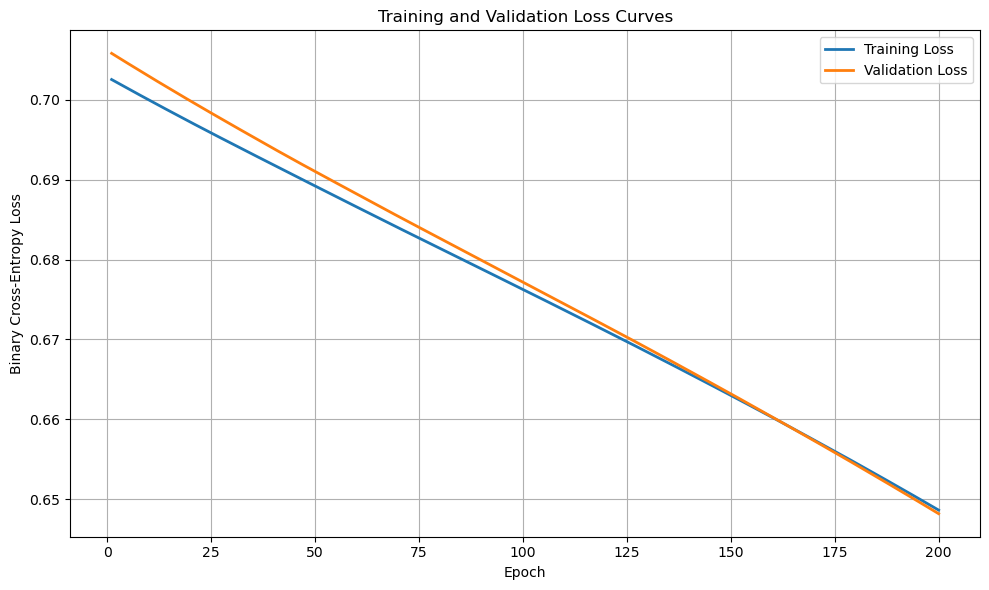

In [13]:
epoch_numbers = range(1, epochs + 1)

plt.figure(figsize=(10, 6))

plt.plot(
    epoch_numbers,
    training_losses,
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epoch_numbers,
    validation_losses,
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Training and Validation Loss Curves")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [14]:
minimum_val_loss = min(validation_losses)
best_epoch = validation_losses.index(minimum_val_loss) + 1

In [15]:
print("\nLearning Trend Analysis")
print("-----------------------")
print(f"Initial Training Loss: {training_losses[0]:.4f}")
print(f"Final Training Loss:   {training_losses[-1]:.4f}")
print(f"Initial Validation Loss: {validation_losses[0]:.4f}")
print(f"Final Validation Loss:   {validation_losses[-1]:.4f}")
print(f"Lowest Validation Loss:  {minimum_val_loss:.4f}")
print(f"Best Epoch:              {best_epoch}")


Learning Trend Analysis
-----------------------
Initial Training Loss: 0.7026
Final Training Loss:   0.6486
Initial Validation Loss: 0.7058
Final Validation Loss:   0.6482
Lowest Validation Loss:  0.6482
Best Epoch:              200


In [16]:
if validation_losses[-1] > minimum_val_loss * 1.05:
    print("Possible overfitting: validation loss increased after its minimum.")
elif training_losses[-1] > training_losses[0]:
    print("Training loss increased; the model may not be learning consistently.")
else:
    print("Training appears to be progressing. Check both curves for generalization.")

Training appears to be progressing. Check both curves for generalization.
